# Generative tagging with Qwen3 — Part A · Training

Qwen3-1.7B-Base, fine-tuned with Hugging Face TRL (QLoRA) to write the tag as text.

**Public Weights & Biases project:** [https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags](https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags)

**Adapter repository:** `rajatsxngh/hw5a-qwen3-base-tag-adapter`

Run this notebook in a **fresh Colab GPU runtime** (A100, L4, or RTX PRO 6000).
Use separate sessions for training and vLLM inference. Add `HF_TOKEN` (with
permission to write the two adapter repositories) and `WANDB_API_KEY` to
Colab Secrets and enable notebook access. Credentials are read without printing
them. The dataset is `multiclass_split.csv` (see `data/README.md`).

## Install the training environment

This notebook fine-tunes the base model with one tag per question, using pinned
package versions. Run this cell before importing the libraries; if
Colab requests a session restart after installation, restart and continue below.
Do not install vLLM in this training runtime.

In [ ]:
import sys, subprocess
packages = [
    "transformers==4.57.6", "datasets==5.0.0", "trl==1.6.0",
    "peft==0.19.1", "accelerate==1.14.0", "evaluate==0.4.6",
    "bitsandbytes==0.49.2", "wandb>=0.19.0", "joblib==1.4.2",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *packages])

0

## Configuration

In [ ]:
import os, json, hashlib, platform, time
from pathlib import Path
import numpy as np
import pandas as pd

PART = 'A'
PHASE = 'training'
SEED = 42
HF_USERNAME = "rajatsxngh"
HF_REPO_ID = 'rajatsxngh/hw5a-qwen3-base-tag-adapter'
HF_PRIVATE = True  # W&B must be public; Hub adapters may remain private.
WANDB_ENTITY = "rajat-utd"
WANDB_PROJECT = "hw5_decoder_tags"
WANDB_PROJECT_URL = 'https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags'
BASE_MODEL = 'Qwen/Qwen3-1.7B-Base'
os.environ["WANDB_ENTITY"] = WANDB_ENTITY
os.environ["WANDB_PROJECT"] = WANDB_PROJECT
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(SEED)
print({"part": PART, "phase": PHASE, "base_model": BASE_MODEL,
       "adapter_repository": HF_REPO_ID, "wandb_project": WANDB_PROJECT_URL})

{'part': 'A', 'phase': 'training', 'base_model': 'Qwen/Qwen3-1.7B-Base', 'adapter_repository': 'rajatsxngh/hw5a-qwen3-base-tag-adapter', 'wandb_project': 'https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags'}


## Authenticate using Colab Secrets

In [ ]:
from google.colab import userdata
from huggingface_hub import login, HfApi
import wandb

def read_secret(name):
    try:
        value = userdata.get(name)
    except Exception:
        raise RuntimeError(
            f"Add {name} in Colab's Secrets panel and enable notebook access."
        ) from None
    if not value:
        raise RuntimeError(f"Colab Secret {name} is empty.")
    return value

os.environ["HF_TOKEN"] = read_secret("HF_TOKEN")
os.environ["WANDB_API_KEY"] = read_secret("WANDB_API_KEY")
login(token=os.environ["HF_TOKEN"], add_to_git_credential=False)
hf_api = HfApi(token=os.environ["HF_TOKEN"])
identity = hf_api.whoami()
assert identity["name"] == HF_USERNAME, "Sign in to the intended Hugging Face account."
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("Authenticated with Hugging Face and Weights & Biases.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rajat7 (rajat-utd) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Authenticated with Hugging Face and Weights & Biases.


## Load and validate the original data splits

In [ ]:
from google.colab import drive, files
drive.mount("/content/drive")
WORK_DIR = Path("/content/drive/MyDrive/HW5_Decoder_Tags")
RESULTS_DIR = WORK_DIR / "results"
WORK_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = WORK_DIR / "multiclass_split.csv"
if not CSV_PATH.exists():
    print("Select the instructor's multiclass_split.csv. It will be saved to Drive for all four notebooks.")
    uploaded = files.upload()
    if "multiclass_split.csv" not in uploaded:
        raise FileNotFoundError("Upload the file named multiclass_split.csv.")
    CSV_PATH.write_bytes(uploaded["multiclass_split.csv"])
    del uploaded

DATASET_SHA256 = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
df = pd.read_csv(CSV_PATH)
required = {"id", "text", "tag", "label", "split", "decoder_train", "val_subset"}
assert required <= set(df.columns), f"Missing columns: {required - set(df.columns)}"
assert not df[["id", "text", "tag", "label", "split"]].isna().any().any()
assert df["id"].is_unique, "Question IDs must be unique."
assert df.groupby("label")["tag"].nunique().eq(1).all()
assert df.groupby("tag")["label"].nunique().eq(1).all()
class_names = df.drop_duplicates("label").sort_values("label")["tag"].tolist()
assert len(class_names) == 10
train_df = df.loc[df["decoder_train"].eq(1)].copy().reset_index(drop=True)
monitor_df = df.loc[df["val_subset"].eq(1)].copy().reset_index(drop=True)
val_df = df.loc[df["split"].eq("val")].copy().reset_index(drop=True)
test_df = df.loc[df["split"].eq("test")].copy().reset_index(drop=True)
assert (len(train_df), len(monitor_df), len(val_df), len(test_df)) == (5000, 1000, 6276, 6275)
assert train_df["split"].eq("train").all()
assert monitor_df["split"].eq("val").all()
assert set(train_df["id"]).isdisjoint(val_df["id"])
assert set(train_df["id"]).isdisjoint(test_df["id"])
assert set(val_df["id"]).isdisjoint(test_df["id"])
assert set(monitor_df["id"]) <= set(val_df["id"])

# These exact functions are embedded identically in all four notebooks.
# Raw text is preserved; do not strip, clean, or add a trailing space.
def make_user_prompt(text):
    return f"Classify the TEXT by selecting one label from the following list: {class_names}. ### TEXT: {text}"

def make_base_prompt(text):
    return make_user_prompt(text) + " ### LABEL:"

print("Dataset:", CSV_PATH)
print("SHA-256:", DATASET_SHA256)
print("Classes:", class_names)
display(pd.DataFrame({"split": ["decoder_train", "val_subset", "validation", "test"],
                      "questions": [len(train_df), len(monitor_df), len(val_df), len(test_df)]}))

Mounted at /content/drive
Select the instructor's multiclass_split.csv. It will be saved to Drive for all four notebooks.


Saving multiclass_split.csv to multiclass_split.csv
Dataset: /content/drive/MyDrive/HW5_Decoder_Tags/multiclass_split.csv
SHA-256: 96782bf3e899d577e2c7cbfb23c31ac4f45397b23487697f75e8677d78633c3b
Classes: ['c#', 'java', 'php', 'javascript', 'android', 'jquery', 'c++', 'python', 'iphone', 'asp.net']


,split,questions
0,decoder_train,5000
1,val_subset,1000
2,validation,6276
3,test,6275


## GPU and reproducibility

The pretrained model and tokenizer are pinned to the same Hub revision. The
training timer below covers `trainer.train()`, including scheduled validation
and checkpoint saves. GPU memory is the peak CUDA memory allocated during that
call, reported in GiB (bytes / 1024³), with reserved memory reported separately.

In [ ]:
import torch
import importlib.metadata as metadata
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, set_seed
from peft import LoraConfig, TaskType
from trl import SFTConfig, SFTTrainer
from IPython.display import display

assert torch.cuda.is_available(), "Select a Colab GPU runtime before training."
assert torch.cuda.is_bf16_supported(), "Use a BF16-capable A100, L4, or RTX PRO 6000."
set_seed(SEED)
GPU_NAME = torch.cuda.get_device_name(0)
BASE_REVISION = hf_api.model_info(BASE_MODEL).sha
package_versions = {name: metadata.version(name) for name in
                    ["torch", "transformers", "datasets", "trl", "peft",
                     "accelerate", "bitsandbytes", "wandb"]}
assert package_versions["transformers"] == "4.57.6"
assert package_versions["trl"] == "1.6.0"
print("GPU:", GPU_NAME)
print("GPU capacity (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
print("Base-model revision:", BASE_REVISION)
display(pd.DataFrame(package_versions.items(), columns=["package", "version"]))

GPU: NVIDIA L4
GPU capacity (GiB): 22.03
Base-model revision: ea980cb0a6c2ae4b936e82123acc929f1cec04c1


,package,version
0,torch,2.11.0+cu130
1,transformers,4.57.6
2,datasets,5.0.0
3,trl,1.6.0
4,peft,0.19.1
5,accelerate,1.14.0
6,bitsandbytes,0.49.2
7,wandb,0.28.1


## Prompt/completion data and sequence lengths

The input uses the original `text` column. Each completion is exactly one
leading space followed by the tag. TRL adds the tokenizer's EOS token to the
completion. The same prompt function is used in the inference notebook.
All 6,000 training/monitoring examples are checked before training; none is
filtered or truncated.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, revision=BASE_REVISION)
assert tokenizer.eos_token is not None and tokenizer.eos_token_id is not None
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

def prompt_completion_dataset(frame):
    return Dataset.from_dict({
        "prompt": [make_base_prompt(text) for text in frame["text"]],
        "completion": [" " + tag for tag in frame["tag"]],
    })

train_dataset = prompt_completion_dataset(train_df)
monitor_dataset = prompt_completion_dataset(monitor_df)
length_rows = []
for split_name, dataset in [("training", train_dataset), ("monitoring", monitor_dataset)]:
    prompts = list(dataset["prompt"])
    combined = [p + c + tokenizer.eos_token
                for p, c in zip(prompts, dataset["completion"])]
    prompt_ids = tokenizer(prompts, truncation=False)["input_ids"]
    combined_ids = tokenizer(combined, truncation=False)["input_ids"]
    lengths = [len(ids) for ids in combined_ids]
    assert max(lengths) <= 1024, "A full sequence exceeds max_length; investigate the source data."
    assert all(full[:len(prompt)] == prompt for prompt, full in zip(prompt_ids, combined_ids)),             "Tokenization changed at a prompt/completion boundary."
    length_rows.append({"split": split_name, "examples": len(dataset),
                        "max_prompt_tokens": max(map(len, prompt_ids)),
                        "max_full_sequence_tokens": max(lengths)})
display(pd.DataFrame(length_rows))
print("Prompt ending:", repr(train_dataset[0]["prompt"][-100:]))
print("Completion:", repr(train_dataset[0]["completion"]))

,split,examples,max_prompt_tokens,max_full_sequence_tokens
0,training,5000,589,592
1,monitoring,1000,490,492


Prompt ending: " for='CheckBoxList1_43'&gt;43 \n&lt; /table&gt;\n</code></pre>\n\n<p>Thanks</p>\n\n<p>Mohak</p> ### LABEL:"
Completion: ' asp.net'


## Load the 4-bit base model and configure QLoRA

Only LoRA parameters on the attention and MLP projections are trained; the
pretrained language-model head remains in place. Batch size 8 × 4 accumulation
steps gives an effective batch size of 32. The best checkpoint is chosen by the
lowest monitoring-set loss, with evaluation and saving every 25 optimizer steps.

In [ ]:
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_quant_storage=torch.bfloat16,
)
model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL, revision=BASE_REVISION,
    quantization_config=quantization_config,
    dtype=torch.bfloat16,
    device_map={"": 0},
    attn_implementation="sdpa",
)
model.config.use_cache = False
model.config.pad_token_id = tokenizer.pad_token_id
peft_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=128, lora_alpha=256, lora_dropout=0.01,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    bias="none",
)
CHECKPOINT_DIR = WORK_DIR / "part_a_checkpoints"
ADAPTER_DIR = WORK_DIR / "part_a_best_adapter"
training_args = SFTConfig(
    output_dir=str(CHECKPOINT_DIR),
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=4,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    learning_rate=1e-4,
    weight_decay=0.0,
    optim="adamw_torch",
    max_length=1024,
    packing=False,
    completion_only_loss=True,
    loss_type="nll",
    eval_strategy="steps",
    eval_steps=25,
    save_strategy="steps",
    save_steps=25,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_strategy="steps",
    logging_steps=25,
    report_to="wandb",
    run_name="hw5a_qwen3_base_qlora_training",
    bf16=True,
    fp16=False,
    tf32=False,
    seed=SEED,
    data_seed=SEED,
    prediction_loss_only=True,
    torch_empty_cache_steps=20,
)
wb_run = wandb.init(
    entity=WANDB_ENTITY, project=WANDB_PROJECT,
    name=training_args.run_name, job_type="training", group="HW5A",
    config={"part": "A", "base_model": BASE_MODEL, "base_model_revision": BASE_REVISION,
            "dataset_sha256": DATASET_SHA256, "training_questions": len(train_df),
            "monitoring_questions": len(monitor_df), "lora_r": 128,
            "lora_alpha": 256, "lora_dropout": 0.01, "epochs": 2,
            "micro_batch_size": 8, "gradient_accumulation_steps": 4,
            "learning_rate": 1e-4, "max_length": 1024, "seed": SEED,
            "completion_only_loss": True, "package_versions": package_versions},
)
trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=monitor_dataset,
    peft_config=peft_config,
    processing_class=tokenizer,
)
trainable_parameters = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
trainer.model.print_trainable_parameters()
assert trainable_parameters > 0
assert all("lora_" in name for name, p in trainer.model.named_parameters() if p.requires_grad)
print("Trainable parameters:", f"{trainable_parameters:,}")

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Adding EOS to train dataset:   0%|          | 0/5000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/5000 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

trainable params: 139,460,608 || all params: 1,860,035,584 || trainable%: 7.4977
Trainable parameters: 139,460,608


## Inspect the actual loss mask

This uses the trainer's processed dataset and its real data collator. Labels
equal to `-100` are ignored. The assertions check that the entire prompt is
masked and that the only supervised tokens are the leading-space tag and EOS.
The additional tokenization example will support the comparison questions.

In [ ]:
processed_example = trainer.train_dataset[0]
sample_batch = trainer.data_collator([processed_example])
input_ids = sample_batch["input_ids"][0].tolist()
labels = sample_batch["labels"][0].tolist()
attention = sample_batch["attention_mask"][0].tolist()
example_prompt = make_base_prompt(train_df.iloc[0]["text"])
prompt_ids = tokenizer(example_prompt)["input_ids"]
expected_completion = " " + train_df.iloc[0]["tag"] + tokenizer.eos_token
expected_ids = tokenizer(expected_completion, add_special_tokens=False)["input_ids"]
supervised_positions = [i for i, label in enumerate(labels) if label != -100]
supervised_ids = [labels[i] for i in supervised_positions]
supervised_text = tokenizer.decode(supervised_ids, skip_special_tokens=False)
assert input_ids[:len(prompt_ids)] == prompt_ids
assert labels[:len(prompt_ids)] == [-100] * len(prompt_ids)
assert supervised_ids == expected_ids
assert supervised_ids[-1] == tokenizer.eos_token_id
assert supervised_text == expected_completion
assert all(label == -100 for label, mask in zip(labels, attention) if mask == 0)
assert all(len(item["input_ids"]) <= 1024 for item in trainer.train_dataset)
assert all(len(item["input_ids"]) <= 1024 for item in trainer.eval_dataset)
print("Masked prompt tokens:", len(prompt_ids))
print("Only these tokens contribute to loss:")
display(pd.DataFrame([
    {"position": i, "token_id": labels[i],
     "token": tokenizer.convert_ids_to_tokens(labels[i]),
     "decoded": repr(tokenizer.decode([labels[i]]))}
    for i in supervised_positions
]))
print("Supervised text:", repr(supervised_text))
print("Prompt/answer boundary labels:", labels[max(0, len(prompt_ids)-12):])

whitespace_examples = {}
for text in [" javascript", "javascript"]:
    ids = tokenizer.encode(text, add_special_tokens=False)
    whitespace_examples[text] = {"token_ids": ids, "tokens": tokenizer.convert_ids_to_tokens(ids)}
    print(repr(text), "->", whitespace_examples[text])
masking_evidence = {
    "part": "A", "example_id": int(train_df.iloc[0]["id"]),
    "tag": train_df.iloc[0]["tag"], "prompt_token_count": len(prompt_ids),
    "input_ids": input_ids, "labels": labels,
    "supervised_token_ids": supervised_ids,
    "supervised_tokens": tokenizer.convert_ids_to_tokens(supervised_ids),
    "supervised_text": supervised_text, "eos_token": tokenizer.eos_token,
    "eos_token_id": tokenizer.eos_token_id, "whitespace_examples": whitespace_examples,
}
(RESULTS_DIR / "masking_A.json").write_text(json.dumps(masking_evidence, indent=2), encoding="utf-8")
wb_run.summary["trainable_parameters"] = trainable_parameters
wb_run.summary["supervised_example_text"] = supervised_text

Masked prompt tokens: 410
Only these tokens contribute to loss:


,position,token_id,token,decoded
0,410,438,Ġas,' as'
1,411,79,p,'p'
2,412,5071,.net,'.net'
3,413,151643,<|endoftext|>,'<|endoftext|>'


Supervised text: ' asp.net<|endoftext|>'
Prompt/answer boundary labels: [-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, 438, 79, 5071, 151643]
' javascript' -> {'token_ids': [35710], 'tokens': ['Ġjavascript']}
'javascript' -> {'token_ids': [14073], 'tokens': ['javascript']}


## Train for two epochs and restore the best checkpoint

In [ ]:
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()
start_time = time.perf_counter()
train_result = trainer.train()
torch.cuda.synchronize()
training_time_seconds = time.perf_counter() - start_time
peak_gpu_memory_gb = torch.cuda.max_memory_allocated() / 1024**3
peak_gpu_reserved_gb = torch.cuda.max_memory_reserved() / 1024**3
assert trainer.state.best_model_checkpoint is not None
assert np.isfinite(trainer.state.best_metric)
print("Training time (minutes):", round(training_time_seconds / 60, 3))
print("Peak allocated GPU memory (GiB):", round(peak_gpu_memory_gb, 3))
print("Peak reserved GPU memory (GiB):", round(peak_gpu_reserved_gb, 3))
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best monitoring loss:", trainer.state.best_metric)
display(pd.DataFrame([train_result.metrics]))

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,0.186800,0.131121,0.085515,0.965761,159650.000000
50,0.109400,0.091330,0.097037,0.972115,322486.000000
75,0.116500,0.090801,0.069112,0.971534,483360.000000
100,0.098500,0.076962,0.054499,0.974564,645419.000000
125,0.082000,0.065594,0.071924,0.978293,799051.000000
150,0.078900,0.074452,0.061748,0.976743,958415.000000
175,0.043800,0.069916,0.048629,0.978343,1109373.000000
200,0.022200,0.065534,0.035237,0.981389,1269626.000000
225,0.028600,0.063814,0.034873,0.980740,1428796.000000
250,0.029000,0.067790,0.033258,0.978798,1583832.000000


Training time (minutes): 40.647
Peak allocated GPU memory (GiB): 11.14
Peak reserved GPU memory (GiB): 21.648
Best checkpoint: /content/drive/MyDrive/HW5_Decoder_Tags/part_a_checkpoints/checkpoint-225
Best monitoring loss: 0.06381379067897797


,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss,epoch
0,2438.1265,4.102,0.129,2.968107e+16,0.068478,2.0


## Inspect the training and monitoring curves

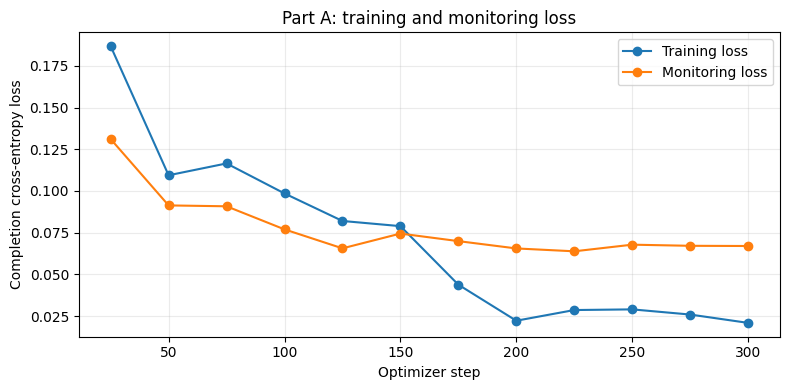

In [11]:
import matplotlib.pyplot as plt
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(RESULTS_DIR / "training_history_A.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
for column, label in [("loss", "Training loss"), ("eval_loss", "Monitoring loss")]:
    points = history.dropna(subset=[column])
    ax.plot(points["step"], points[column], marker="o", label=label)
ax.set(xlabel="Optimizer step", ylabel="Completion cross-entropy loss",
       title="Part A: training and monitoring loss")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_loss_A.png", dpi=160)
wandb.log({"training_loss_curve": wandb.Image(fig)})
plt.show()

## Save the best adapter and upload it to Hugging Face

`load_best_model_at_end=True` has restored the selected checkpoint into the
trainer. `trainer.save_model()` saves that adapter, not the last epoch's weights.
The tokenizer, masking evidence, prompt example, and training summary travel
with the adapter. The uploaded commit hash is then recorded in the Drive
summary so inference can load this exact version.

In [12]:
import shutil
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
trainer.save_model(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))
assert (ADAPTER_DIR / "adapter_config.json").exists()
assert (ADAPTER_DIR / "adapter_model.safetensors").exists()
shutil.copy2(RESULTS_DIR / "masking_A.json", ADAPTER_DIR / "masking_A.json")
training_summary = {
    "part": "A", "base_model": BASE_MODEL,
    "base_model_revision": BASE_REVISION, "model_revision": BASE_REVISION,
    "adapter_repo_id": HF_REPO_ID, "dataset_sha256": DATASET_SHA256,
    "class_names": class_names, "training_questions": len(train_df),
    "monitoring_questions": len(monitor_df),
    "trainable_parameters": trainable_parameters,
    "training_time_seconds": training_time_seconds,
    "peak_gpu_memory_gb": peak_gpu_memory_gb,
    "peak_gpu_reserved_gb": peak_gpu_reserved_gb,
    "gpu_memory_units": "GiB (1024**3 bytes)", "gpu_name": GPU_NAME,
    "best_eval_loss": float(trainer.state.best_metric),
    "best_checkpoint": str(trainer.state.best_model_checkpoint),
    "optimizer_steps": int(trainer.state.global_step),
    "wandb_run_url": wb_run.url, "wandb_project_url": WANDB_PROJECT_URL,
    "prompt_format": "hw5_single_tag_v1",
    "prompt_example_text": train_df.iloc[0]["text"],
    "prompt_example": make_base_prompt(train_df.iloc[0]["text"]),
    "completion_prefix": " ", "eos_token": tokenizer.eos_token,
    "package_versions": package_versions,
}
summary_path = RESULTS_DIR / "training_summary_A.json"
summary_path.write_text(json.dumps(training_summary, indent=2), encoding="utf-8")
(ADAPTER_DIR / "training_summary_A.json").write_text(json.dumps(training_summary, indent=2), encoding="utf-8")
hf_api.create_repo(repo_id=HF_REPO_ID, repo_type="model", private=HF_PRIVATE, exist_ok=True)
upload = hf_api.upload_folder(
    repo_id=HF_REPO_ID, repo_type="model", folder_path=str(ADAPTER_DIR),
    allow_patterns=["adapter_config.json", "adapter_model.safetensors", "tokenizer*",
                    "special_tokens_map.json", "added_tokens.json", "vocab.json", "merges.txt",
                    "chat_template.jinja", "README.md", "training_summary_A.json", "masking_A.json"],
    commit_message="Save HW5A best-loss QLoRA adapter and reproducibility metadata",
)
training_summary["adapter_revision"] = upload.oid
summary_path.write_text(json.dumps(training_summary, indent=2), encoding="utf-8")
wb_run.summary.update({key: training_summary[key] for key in
                      ["trainable_parameters", "training_time_seconds", "peak_gpu_memory_gb",
                       "gpu_name", "best_eval_loss", "adapter_repo_id", "adapter_revision"]})
print("Adapter:", f"https://huggingface.co/{HF_REPO_ID}")
print("Pinned adapter revision:", upload.oid)
print("Training summary:", summary_path)
display(pd.DataFrame([{key: training_summary[key] for key in
                       ["training_questions", "trainable_parameters", "training_time_seconds",
                        "peak_gpu_memory_gb", "best_eval_loss"]}]))
wb_run.finish()

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          | 27.6kB /  558MB            

  ...st_adapter/tokenizer.json:   0%|          | 28.3kB / 11.4MB            

Adapter: https://huggingface.co/rajatsxngh/hw5a-qwen3-base-tag-adapter
Pinned adapter revision: e6830856e4882d402b245a972d3df87aac01f702
Training summary: /content/drive/MyDrive/HW5_Decoder_Tags/results/training_summary_A.json


,training_questions,trainable_parameters,training_time_seconds,peak_gpu_memory_gb,best_eval_loss
0,5000,139460608,2438.7957,11.140435,0.063814


eval/entropy,▇█▅▃▅▄▃▁▁▁▁▁
eval/loss,█▄▄▂▁▂▂▁▁▁▁▁
eval/mean_token_accuracy,▁▄▄▅▇▆▇██▇▇▇
eval/num_tokens,▁▂▂▃▄▄▅▅▆▇▇█
eval/runtime,▅▂▂▄▂▁▃▃█▄█▄
eval/samples_per_second,▄▇▇▅▇█▆▆▁▅▁▅
eval/steps_per_second,▄▇▇▄▇█▆▇▁▅▁▅
train/entropy,█▃▄▄▃▃▂▁▁▁▁▁
train/epoch,▁▁▂▂▂▂▃▃▃▃▄▄▅▅▅▅▆▆▆▆▇▇███
train/global_step,▁▁▂▂▂▂▃▃▃▃▄▄▅▅▅▅▆▆▆▆▇▇████
+5,...


## Continue with Part A inference

Save this notebook with its outputs, then disconnect/delete this runtime and
open `02_base_vllm_inference.ipynb` in a fresh GPU session. That notebook
loads the saved adapter from Hugging Face and evaluates it with vLLM.

References:
[TRL SFTTrainer v1.6.0](https://huggingface.co/docs/trl/v1.6.0/en/sft_trainer);
[Hugging Face Hub uploads](https://huggingface.co/docs/huggingface_hub/guides/upload).